In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm

# Reading the diamonds dataset
df = pd.read_csv(r'C:\Users\Lakshin Khurana\Downloads\diamonds.csv')

# Displaying the first few rows to understand the data
df.head()


,Unnamed: 0,carat,cut,depth,table,price,x,y,z
0,1,0.23,Ideal,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,63.3,58.0,335,4.34,4.35,2.75


In [3]:
df.columns
num_rows = df.shape[0]
num_rows


53940

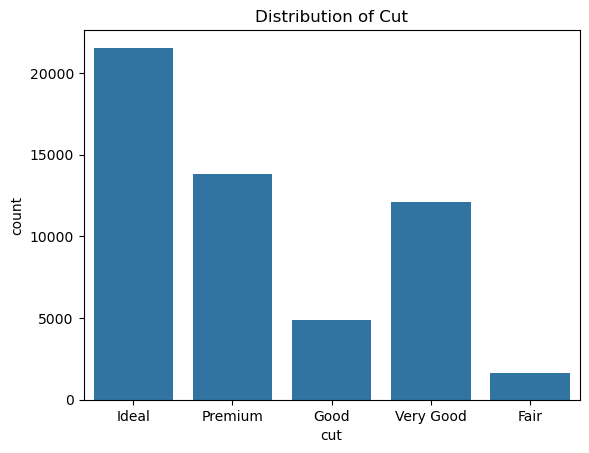

In [4]:
sns.countplot(x='cut', data=df)
plt.title('Distribution of Cut')
plt.show()


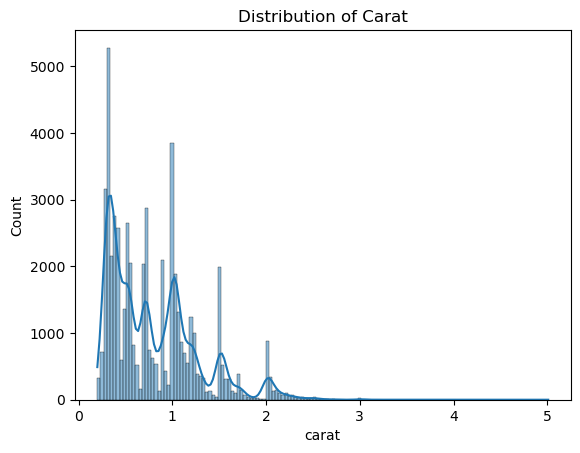

In [5]:
sns.histplot(df['carat'], kde=True)
plt.title('Distribution of Carat')
plt.show()


In [6]:
df.describe()


,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [7]:
X = df.drop('price', axis=1)
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


In [8]:
X_train_reg = X_train[['carat', 'table', 'x', 'y', 'z']]
X_test_reg = X_test[['carat', 'table', 'x', 'y', 'z']]
lm = LinearRegression()
lm.fit(X_train_reg, y_train)
y_pred = lm.predict(X_test_reg)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2, mse, rmse


(0.8560120720408737, 2245630.448291138, 1498.5427749287433)

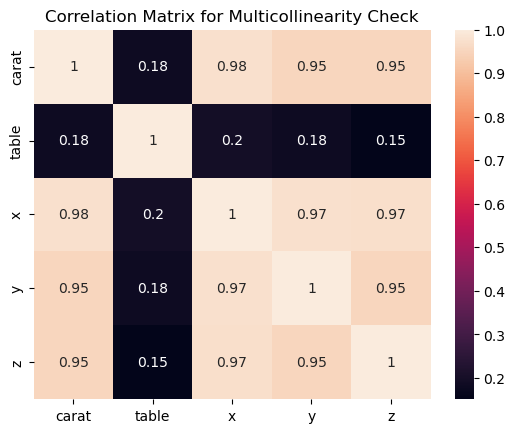

In [9]:
corr_matrix = df[['carat', 'table', 'x', 'y', 'z']].corr()
sns.heatmap(corr_matrix, annot=True)
plt.title('Correlation Matrix for Multicollinearity Check')
plt.show()


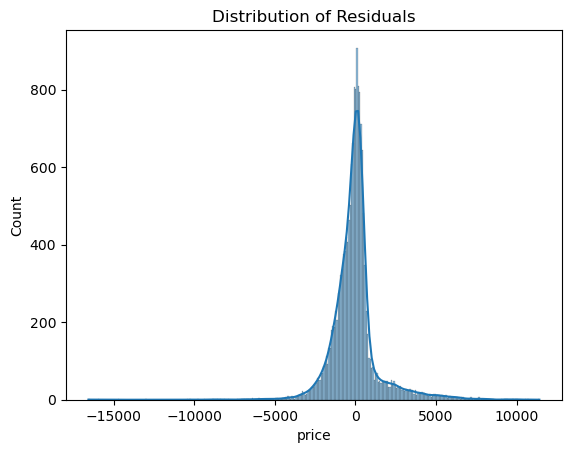

In [10]:
residuals = y_test - y_pred
sns.histplot(residuals, kde=True)
plt.title('Distribution of Residuals')
plt.show()


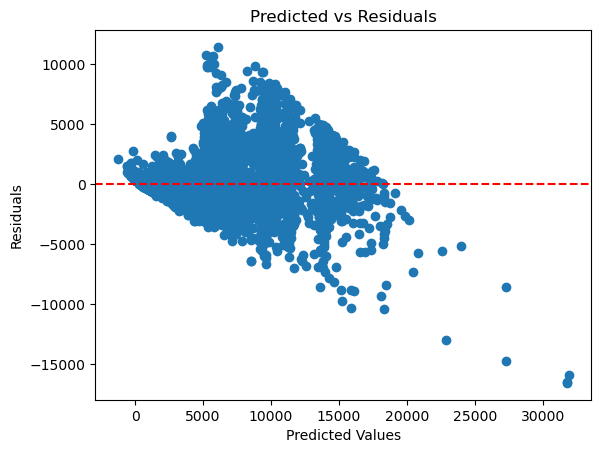

In [12]:
plt.scatter(y_pred, residuals)
plt.title('Predicted vs Residuals')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.axhline(0, color='red', linestyle='--')
plt.show()


In [13]:
X_test_sm = sm.add_constant(X_test_reg)
model = sm.OLS(y_test, X_test_sm).fit()
r_squared = model.rsquared
adj_r_squared = model.rsquared_adj
r_squared, adj_r_squared


(0.8581433246095711, 0.8580994767252392)

In [14]:
features = np.array([0.25, 55, 4, 4.2, 2.5]).reshape(1, -1)
predicted_price = lm.predict(features)
predicted_price


c:\Users\Lakshin Khurana\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([297.42199887])